In [7]:
# ==============================================================================
# Import modules
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import warnings 
 
warnings.filterwarnings('ignore')

# ==============================================================================
# Load data and select features 
# Split into training and test data
# ==============================================================================
data = datasets.load_breast_cancer()
X = data.data
y = data.target

# Split data into a total training set and final test set (70% training, 30% test)
X_train_tot, X_test_final, y_train_tot, y_test_final = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)



Average test accuracy across 100 splits for l1 with C=10^-8.0 is 0.625 +/- 0.000
Average train accuracy across 100 splits for l1 with C=10^-8.0 is 0.629 +/- 0.000
Average test accuracy across 100 splits for l1 with C=10^-7.0 is 0.625 +/- 0.000
Average train accuracy across 100 splits for l1 with C=10^-7.0 is 0.629 +/- 0.000
Average test accuracy across 100 splits for l1 with C=10^-6.0 is 0.625 +/- 0.000
Average train accuracy across 100 splits for l1 with C=10^-6.0 is 0.629 +/- 0.000
Average test accuracy across 100 splits for l1 with C=10^-5.0 is 0.625 +/- 0.000
Average train accuracy across 100 splits for l1 with C=10^-5.0 is 0.629 +/- 0.000
Average test accuracy across 100 splits for l1 with C=10^-4.0 is 0.625 +/- 0.000
Average train accuracy across 100 splits for l1 with C=10^-4.0 is 0.629 +/- 0.000
Average test accuracy across 100 splits for l1 with C=10^-3.0 is 0.625 +/- 0.000
Average train accuracy across 100 splits for l1 with C=10^-3.0 is 0.629 +/- 0.000
Average test accuracy 

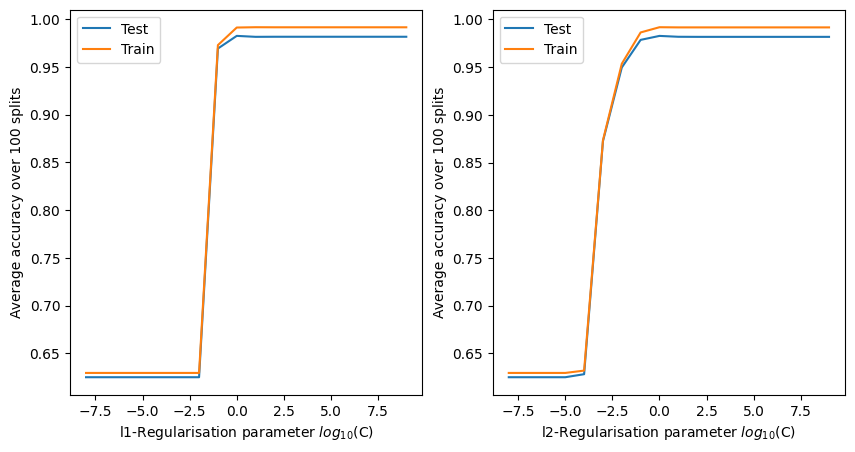

In [8]:
# ==============================================================================
# Train Logistic Regression models with different regularisation parameters
# ==============================================================================

Average_test_accuracy={}
Average_train_accuracy={}
use_c={}
sc = StandardScaler()

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for ax, penalty in zip(ax, ["l1", "l2"]): # Loop through with both l1 and l2 regularisation
    c_range = np.arange(-8, 10, 1.0)
    accuracy = np.zeros(shape=(2, len(c_range)))
    
    Average_test_accuracy[penalty]={}
    Average_train_accuracy[penalty]={}
    for index, c in enumerate(c_range): # Loop through different regularisation strengths
        test_accuracies = []
        train_accuracies = []
        for seed in range(1,101): # Run through 100 different test-train splits
            
            # Split data into training and test data (70% training, 30% test)
            X_train, X_test, y_train, y_test = train_test_split(X_train_tot, y_train_tot, test_size=0.3, random_state=seed, stratify=y_train_tot)
    
            # Initialise Logistic regression with the given regularisation strength
            clf = LogisticRegression(max_iter=100, solver='saga', penalty=penalty, random_state=102, C=10.0**c)
    
            
            # Scale features using StandardScaler class in scikit-learn
            sc.fit(X_train)
        
            X_train_sc = sc.transform(X_train)
            X_test_sc = sc.transform(X_test)
            
            clf.fit(X_train_sc, y_train) # Fit the classification model
    
            # Save the test and training scores
            test_score = clf.score(X_test_sc, y_test)
            train_score = clf.score(X_train_sc, y_train)
            test_accuracies.append(test_score)
            train_accuracies.append(train_score)
            
        accuracy[0, index] = np.mean(test_accuracies)
        accuracy[1, index] = np.mean(train_accuracies)
        
        Average_test_accuracy[penalty][str(c)]=np.mean(test_accuracies)
        Average_train_accuracy[penalty][str(c)]=np.mean(train_accuracies)
        
        print(
        f"Average test accuracy across 100 splits for {penalty} with C=10^{c}"
        f" is {np.mean(test_accuracies):.3f} +/- {np.std(test_accuracies):.3f}"
        )
    
        print(
        f"Average train accuracy across 100 splits for {penalty} with C=10^{c}"
        f" is {np.mean(train_accuracies):.3f} +/- {np.std(train_accuracies):.3f}"
        )

    # Plot accuracy vs. C
    ax.plot(c_range, accuracy[0], label="Test")
    ax.plot(c_range, accuracy[1], label="Train")
    ax.set_xlabel(f"{penalty}-Regularisation parameter $log_{{10}}$(C)")
    ax.set_ylabel("Average accuracy over 100 splits")
    ax.legend()   


    print(f"Most accurate classifier across 100 splits for {penalty}: C = 10^{max(Average_test_accuracy[penalty], key=Average_test_accuracy[penalty].get)}")
    use_c[penalty]=float(max(Average_test_accuracy[penalty], key=Average_test_accuracy[penalty].get))
    
    print(f"Accuracy from validation: {Average_test_accuracy[penalty][str(use_c[penalty])]:.3f}")
    

Misclassified samples in the final test set for l1-regularisation: 7
Accuracy for the final test set for l1-regularisation: 0.959
Number of zero weights for l1-regularisation: 8
Misclassified samples in the final test set for l2-regularisation: 6
Accuracy for the final test set for l2-regularisation: 0.965
Number of zero weights for l2-regularisation: 0
Number of retained features after filtering: 27
Misclassified samples in the final test set for l2-regularisation with reduced feature set: 6
Accuracy for the final test set for l2-regularisation with reduced feature set: 0.965


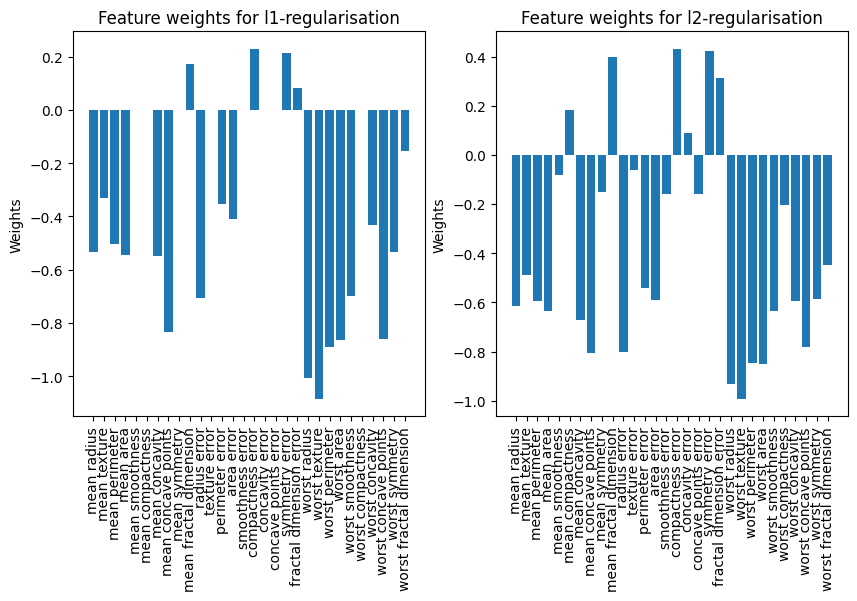

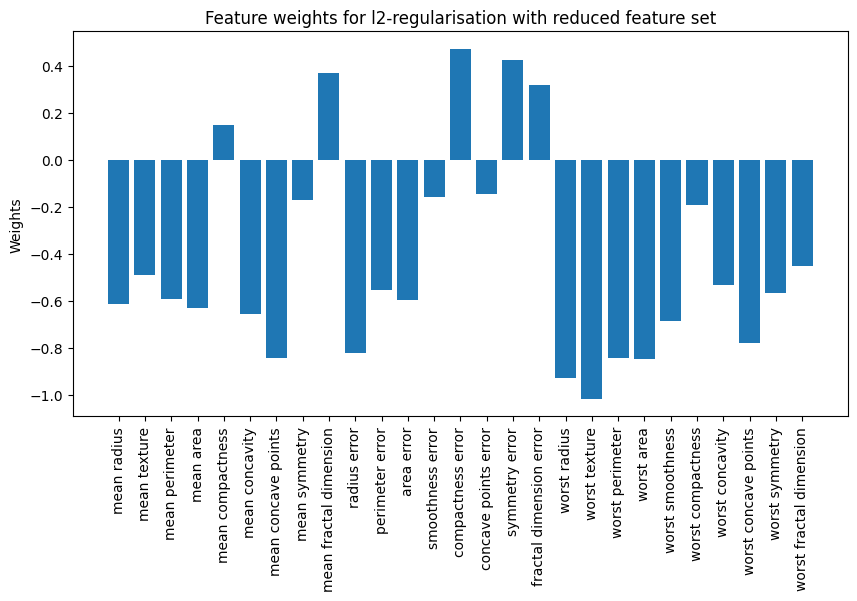

In [9]:
#---------------------------------------------------------------------------
# Final modelling using the best models for both l1 and l2 regularisation
#---------------------------------------------------------------------------

# Standardise the data with parameters found using the total training set
sc.fit(X_train_tot)

X_train_tot_sc = sc.transform(X_train_tot)
X_test_final_sc = sc.transform(X_test_final)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for ax, penalty in zip(ax, ["l1", "l2"]):
    c=use_c[penalty]

    use_clf=LogisticRegression(max_iter=100, solver='saga', penalty=penalty, random_state=103, C=10.0**c)

    # Fit the best model on the entire training set
    use_clf.fit(X_train_tot_sc, y_train_tot)
    
    # Predict classes for samples in the final test set and print the number of misclassfications
    y_pred_final = use_clf.predict(X_test_final_sc)
    
    print(f"Misclassified samples in the final test set for {penalty}-regularisation: {(y_test_final != y_pred_final).sum()}")
    # Print accuracy computed from predictions on the final test set
    print(f"Accuracy for the final test set for {penalty}-regularisation: {use_clf.score(X_test_final_sc, y_test_final):.3f}")
    
    # Plot the weights
    weights = use_clf.coef_[0]
    print(f"Number of zero weights for {penalty}-regularisation: {np.sum(np.abs(weights) < 1e-2)}")
    
    ax.bar(data.feature_names, weights)
    ax.tick_params(axis='x', rotation=90)
    ax.set_ylabel("Weights")
    ax.set_title(f"Feature weights for {penalty}-regularisation")

    #Using l2-regularisation for feature selection
    if penalty=="l2":
        # Filtering according to absolute values of the weights, to take out the features having low absolute values of the weights
        keep_features=np.where(np.abs(weights) > 0.2*np.mean(np.abs(weights))) #The threshold for how large the absolute values of the weights 
                                                #should be for the features to be included in the model can be optimised (not done here)
        keep_features=keep_features[0]
        
        print(f"Number of retained features after filtering: {len(keep_features)}")
        
        # Fit the best model on the entire training set using a reduced feature set
        use_clf.fit(X_train_tot_sc[:, keep_features], y_train_tot)
        
        # Predict classes for samples in the final test set and print the number of misclassfications
        y_pred_final = use_clf.predict(X_test_final_sc[:, keep_features])
        
        print(f"Misclassified samples in the final test set for {penalty}-regularisation with reduced feature set: {(y_test_final != y_pred_final).sum()}")
    
        # Print accuracy computed from predictions on the final test set
        print(f"Accuracy for the final test set for {penalty}-regularisation with reduced feature set: {use_clf.score(X_test_final_sc[:, keep_features], y_test_final):.3f}")
    
        # Plot the weights
        weights = use_clf.coef_[0]
        
        fig, ax2 = plt.subplots(1, 1, figsize=(10, 5))
        ax2.bar(data.feature_names[keep_features], weights)
        ax2.tick_params(axis='x', rotation=90)
        ax2.set_ylabel("Weights")
        ax2.set_title(f"Feature weights for {penalty}-regularisation with reduced feature set")
        